In [21]:
%pip install pandas matplotlib seaborn


Note: you may need to restart the kernel to use updated packages.


In [22]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from scipy.cluster.hierarchy import dendrogram, linkage,cophenet
from scipy.spatial.distance import pdist
from sklearn.decomposition import PCA

In [23]:
import sys
!{sys.executable} -m pip install scikit-learn


In [24]:
country_df = pd.read_csv(r'C:\Users\USER\Documents\Country_Data\Rawdata\Country-data.csv')

In [25]:
country_df.head()

,country,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp
0,Afghanistan,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553
1,Albania,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090
2,Algeria,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460
3,Angola,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530
4,Antigua and Barbuda,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200


##basic checks

In [26]:
def basic_checks(dataframe):
    print('shape \n', dataframe.shape)
    print( 'Duplicate \n', dataframe.duplicated().sum())
    print('data types \n', dataframe.dtypes)
    print('Missing values \n', dataframe.isnull().sum())
    print("DataFrame Info:")
    print(dataframe.info())
    print("\nMissing Values:")
    print(dataframe.isnull().sum())
    print("\nDescriptive Statistics:")
    print(dataframe.describe())

In [27]:
basic_checks(country_df)

shape 
 (167, 10)
Duplicate 
 0
data types 
 country           str
child_mort    float64
exports       float64
health        float64
imports       float64
income          int64
inflation     float64
life_expec    float64
total_fer     float64
gdpp            int64
dtype: object
Missing values 
 country       0
child_mort    0
exports       0
health        0
imports       0
income        0
inflation     0
life_expec    0
total_fer     0
gdpp          0
dtype: int64
DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 167 entries, 0 to 166
Data columns (total 10 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   country     167 non-null    str    
 1   child_mort  167 non-null    float64
 2   exports     167 non-null    float64
 3   health      167 non-null    float64
 4   imports     167 non-null    float64
 5   income      167 non-null    int64  
 6   inflation   167 non-null    float64
 7   life_expec  167 non-null    float64
 8   total_

###Explanatory Data Analysis (EDA)

In [28]:
country_df = country_df.drop(columns=['country'])

In [29]:
country_df['country'] = original_series = pd.read_csv(r'C:\Users\USER\Documents\Country_Data\Rawdata\Country-data.csv')['country']


In [30]:
features_df = country_df.select_dtypes(include=['float64', 'int64']).columns

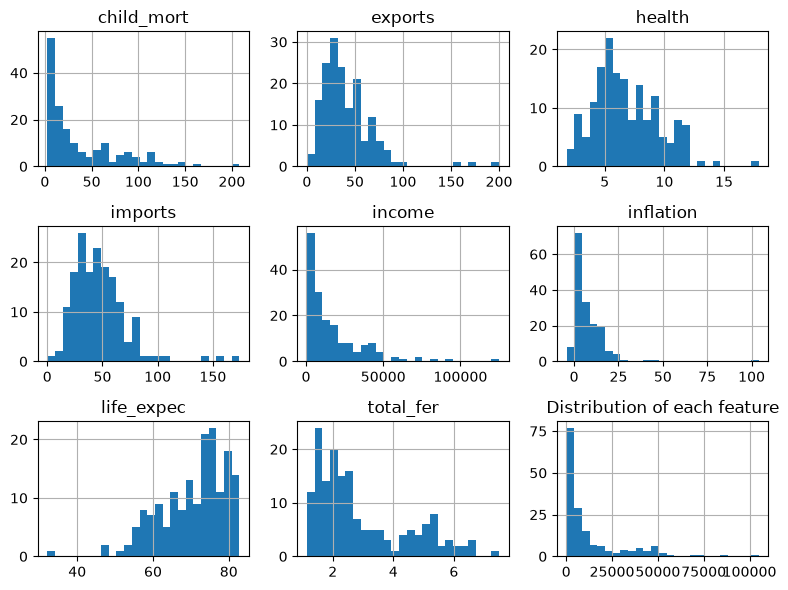

In [31]:
# plotting a histogram to show the shape of distribution of the data
country_df.hist(bins=25, figsize=(8, 6))
plt.title('Distribution of each feature')
plt.tight_layout()
plt.show()


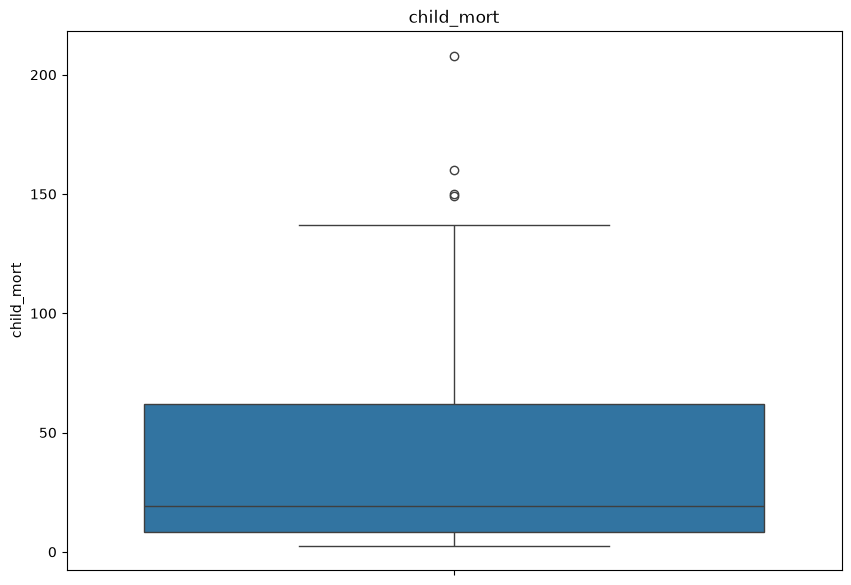

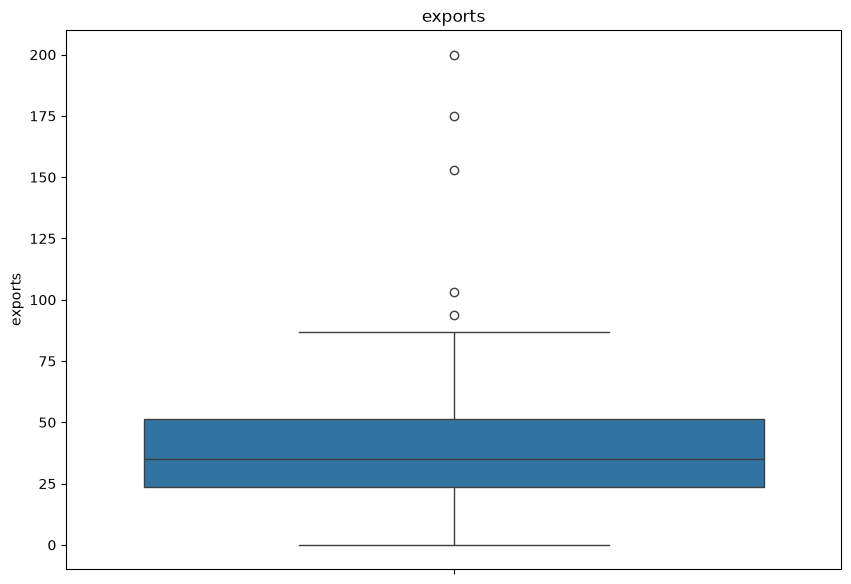

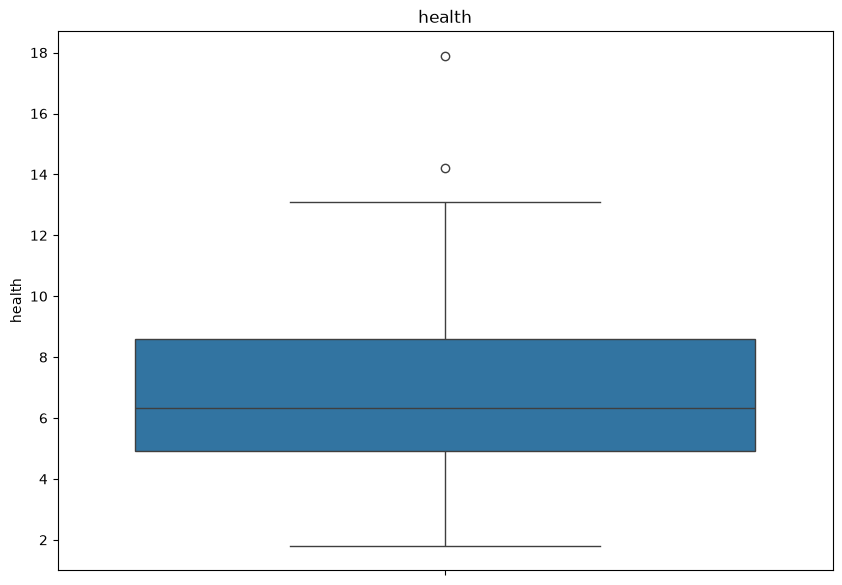

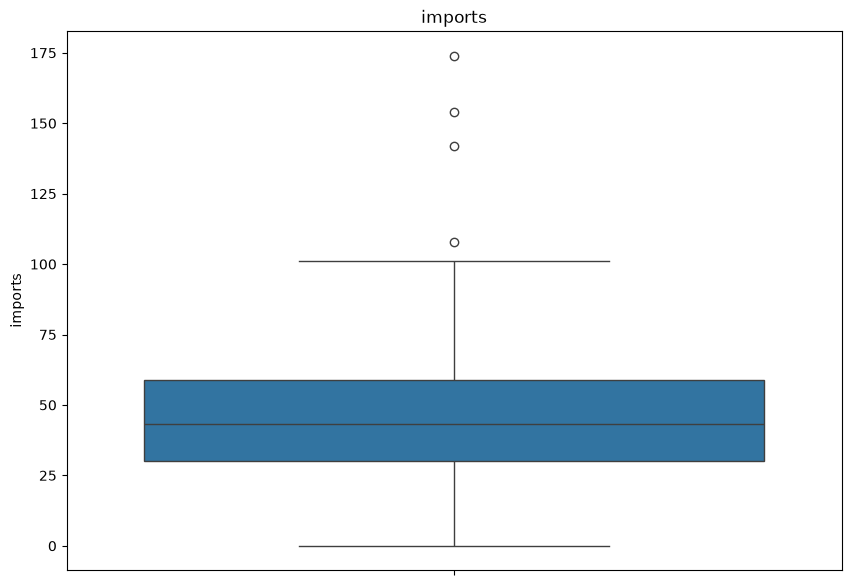

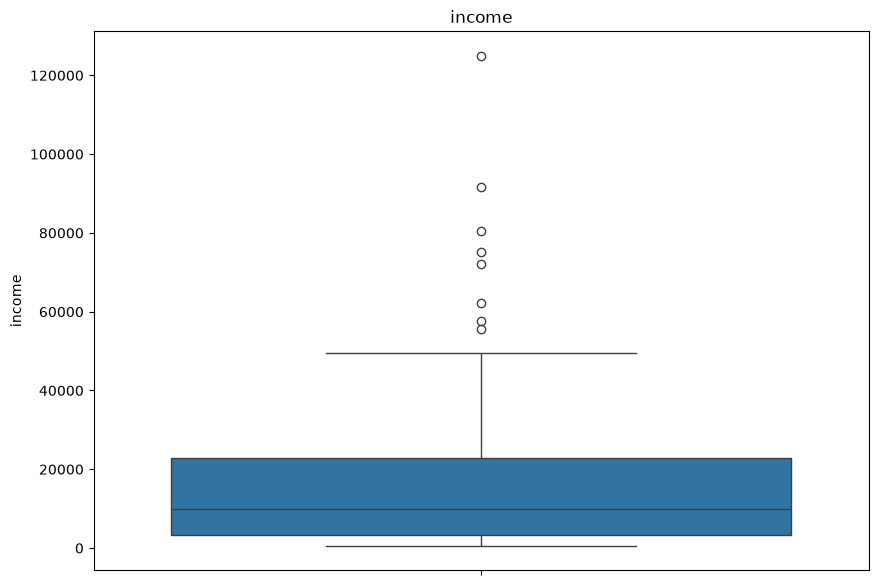

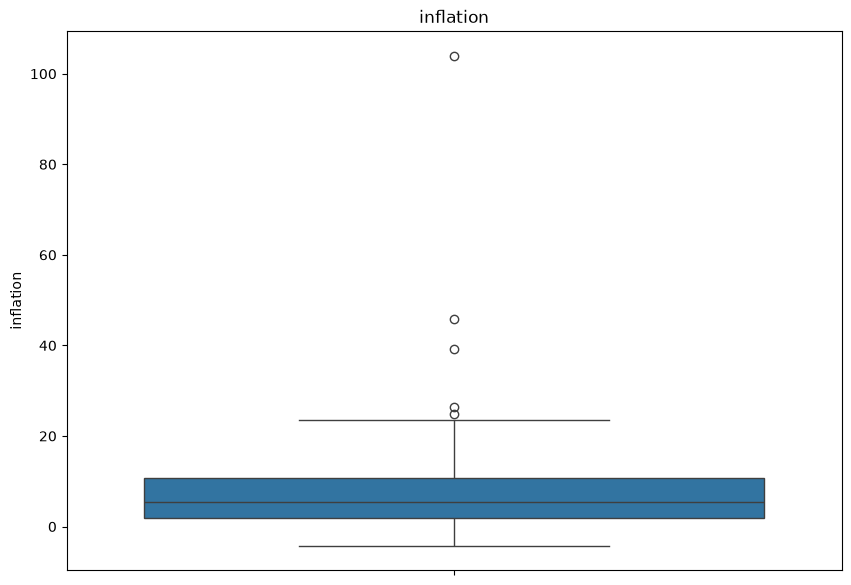

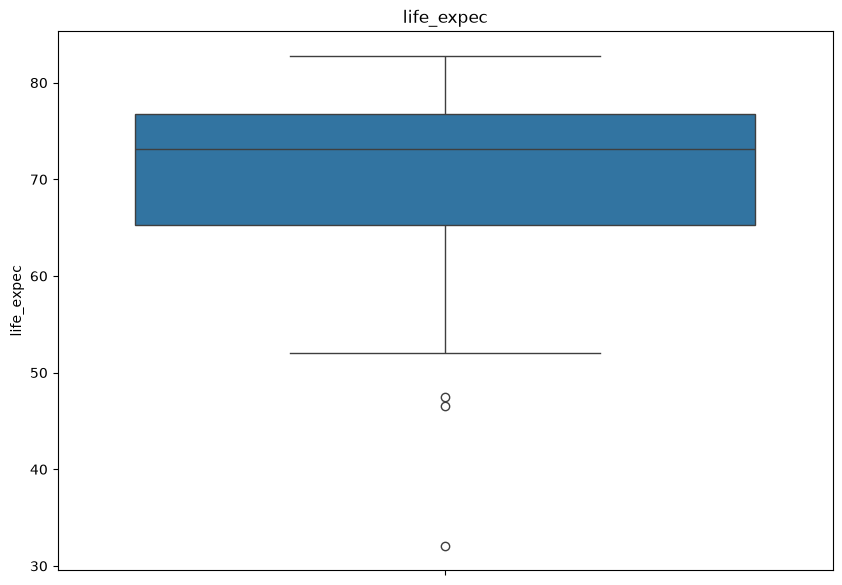

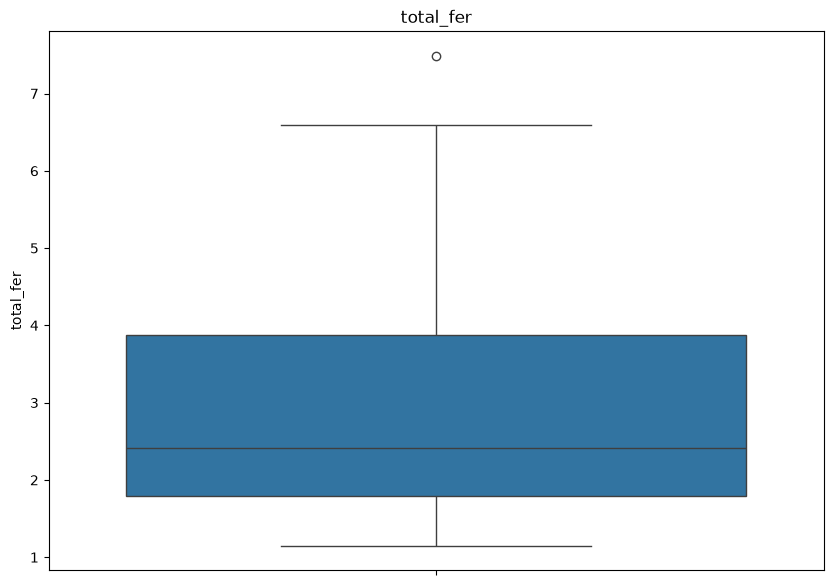

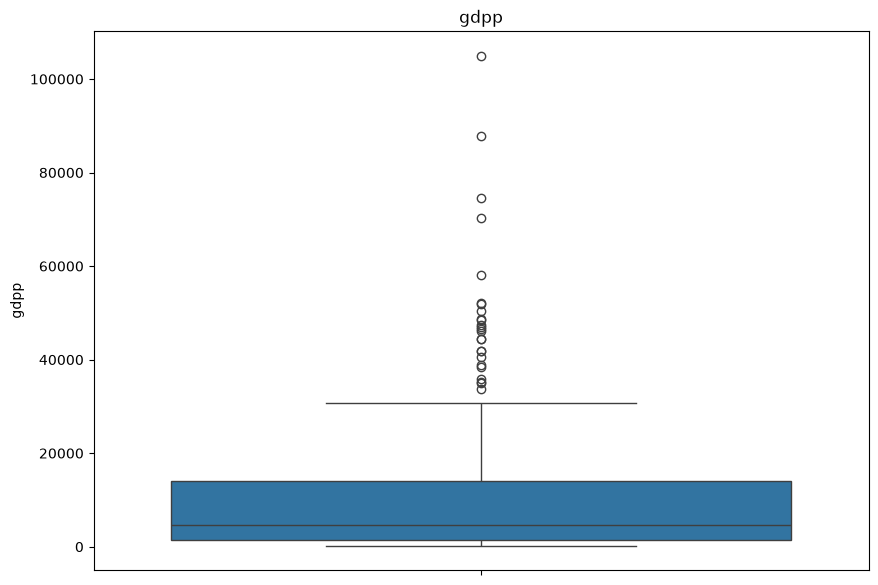

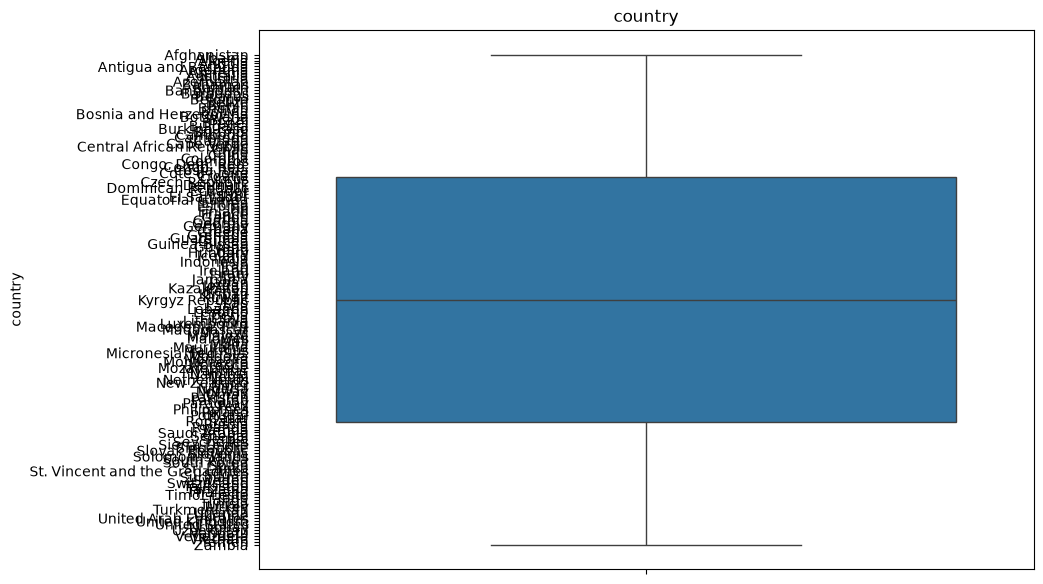

In [32]:
## plotting the boxplot for outlier
for column in country_df.columns.to_list():
    plt.figure(figsize=(10, 7))
    sns.boxplot(data=country_df, y=column)
    plt.title(column)
    plt.show()
    

Correalation anlysis

In [41]:
correlation = country_df.corr(method='spearman')
correlation

plt.figure(figsize=(8, 6))
sns.heatmap(correlation, annot=True, fmt='.2f')
plt.title('Correlation')
plt.show()

ValueError: could not convert string to float: 'Afghanistan'

##Pre-processing(Scaling)

In [46]:
#Instatiate the std scaler class
scaler = StandardScaler()

#Scale the dataset
X=scaler.fit_transform(country_df)

#Viewing our data inform of dataframe
X 

ValueError: could not convert string to float: 'Afghanistan'

In [44]:
features_names = country_df.columns.to_list()

In [45]:

#Viewing our data inform of dataframe
x = pd.DataFrame(X, columns=features_names, index=country_df.index)
x.head() 

NameError: name 'X' is not defined

K-Means Clustering

Method 1: Elbow Metond

In [ ]:
k_range = range(1, 11)
inertias = []
for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(X)
    inertias.append(km.inertia_)

plt.figure(figsize=(9, 5))
plt.plot(list(k_range), inertias, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Inertia(wcss)')
plt.title('Elbow Method')
plt.xticks(list(k_range))
plt.show()


NameError: name 'X' is not defined

Method 2: Silhouette score

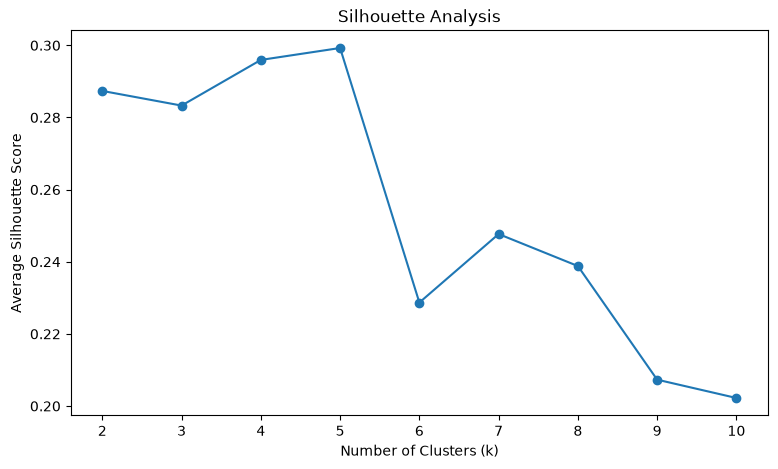

In [ ]:
sil_range = range(2, 11)
sil_score = []

for k in sil_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    sil_score.append(silhouette_score(X, labels))

plt.figure(figsize=(9, 5))
plt.plot(list(sil_range), sil_score, marker='o')
plt.xlabel('Number of Clusters (k)')
plt.ylabel('Average Silhouette Score')
plt.title('Silhouette Analysis')
plt.show()
    

Fitting the final K-Means model

In [ ]:
K = 4
#Fitting the model
kmeans = KMeans(n_clusters=K, random_state=42, n_init=10)

kmeans_clusters = kmeans.fit_predict(X)

#Attaching the cluster number to the original dataframe
country_df['kmeansCluster'] = kmeans_clusters
country_df.head()

,child_mort,exports,health,imports,income,inflation,life_expec,total_fer,gdpp,kmeansCluster
0,90.2,10.0,7.58,44.9,1610,9.44,56.2,5.82,553,1
1,16.6,28.0,6.55,48.6,9930,4.49,76.3,1.65,4090,2
2,27.3,38.4,4.17,31.4,12900,16.10,76.5,2.89,4460,2
3,119.0,62.3,2.85,42.9,5900,22.40,60.1,6.16,3530,1
4,10.3,45.5,6.03,58.9,19100,1.44,76.8,2.13,12200,2


In [43]:
pip show scipy

Name: scipy
Version: 1.18.0
Summary: Fundamental algorithms for scientific computing in Python
Home-page: https://scipy.org/
Author: 
Author-email: 
License: Copyright (c) 2001-2002 Enthought, Inc. 2003, SciPy Developers.
 All rights reserved.

 Redistribution and use in source and binary forms, with or without
 modification, are permitted provided that the following conditions
 are met:

 1. Redistributions of source code must retain the above copyright
    notice, this list of conditions and the following disclaimer.

 2. Redistributions in binary form must reproduce the above
    copyright notice, this list of conditions and the following
    disclaimer in the documentation and/or other materials provided
    with the distribution.

 3. Neither the name of the copyright holder nor the names of its
    contributors may be used to endorse or promote products derived
    from this software without specific prior written permission.

 THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS A

#Hierarchical clustering

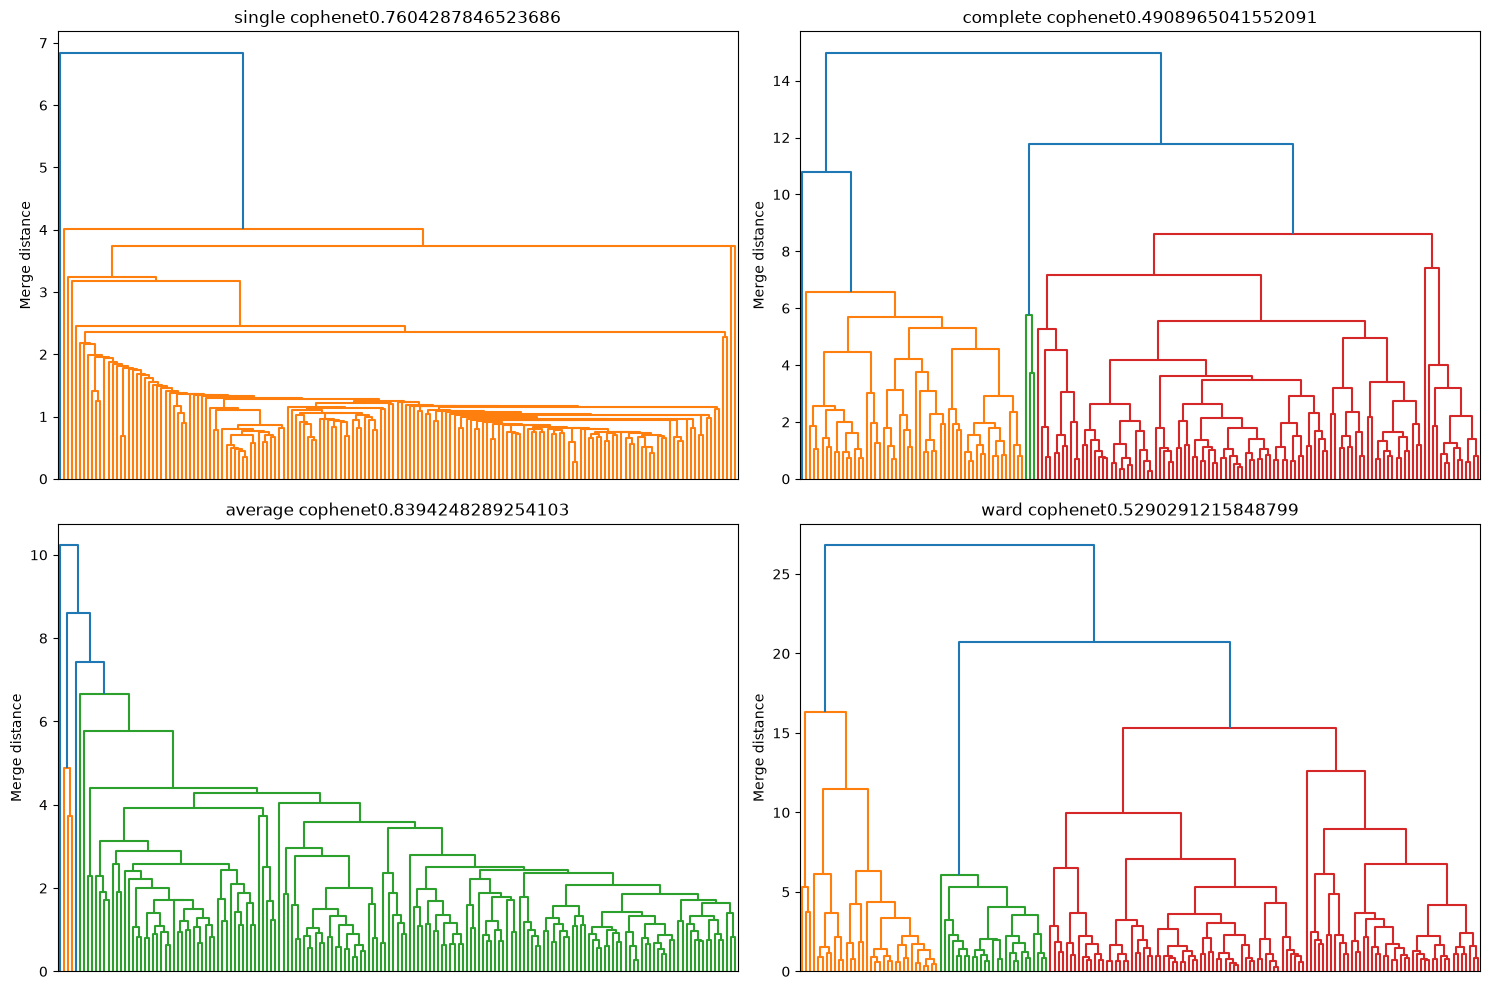

In [ ]:
Linkage_methods = ['single', 'complete', 'average', 'ward'] 

fig, axes = plt.subplots(2, 2, figsize=(15, 10)) 
for ax, method in zip(axes.flatten(), Linkage_methods):
    Z = linkage(X, method=method)
    dendrogram(Z, ax=ax, no_labels=True,)
    ax.set_title(f'Dendrogram ({method} linkage)')   

#The cophenetic correlation coefficient is a measure of how faithfully a dendrogram preserves the pairwise distances between the original data points. It is calculated by comparing the cophenetic distances (the heights at which pairs of points are merged in the dendrogram) with the original pairwise distances.
#Closer to 1 means the dendrogram is a good representation of the data, while closer to 0 means it is not.
#The cophenetic correlation coefficient measures how faithfuly the tress preserves the pairwise distances between the original data points. It is calculated by comparing the cophenetic distances (the heights at which pairs of points are merged in the dendrogram) with the original pairwise distances. A value closer to 1 indicates that the dendrogram is a good representation of the data, while a value closer to 0 indicates that it is not. Closer to 1 is better. 
    c,_=cophenet(Z,pdist(x))
    ax.set_title(f'{method} cophenet{c}')
    ax.set_ylabel('Merge distance')
plt.tight_layout()
plt.show()


### Bulding the final dendrogram

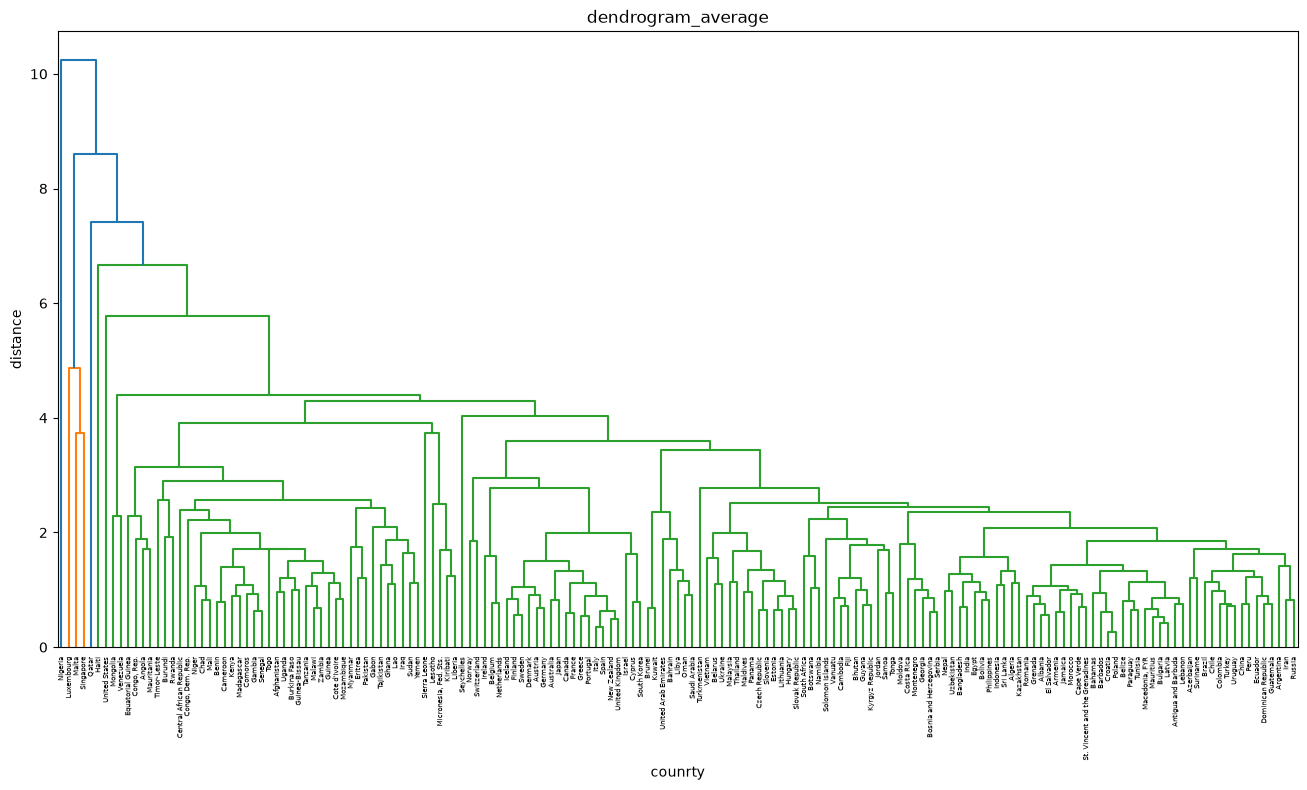

In [ ]:
z=linkage(x,method='average')
plt.figure(figsize=(16,8))
dendrogram(z,labels=country_df['country'].values,leaf_rotation=90,leaf_font_size=8)
plt.title('dendrogram_average')
plt.xlabel('counrty')
plt.ylabel('distance')
plt.show()

In [ ]:
z=linkage(x,method='ward')
plt.figure(figsize=(16,8))
dendrogram(z,labels=country_df['country'].values,leaf_rotation=90,leaf_font_size=8)
plt.title('dendrogram_average')
plt.xlabel('counrty')
plt.ylabel('distance')
plt.show()

NameError: name 'x' is not defined

In [42]:
pca_all = PCA()
x_pca_all = pca_all.fit_transform(X)

print('original_number of fetures: ',X.shape[1])
print('Number of pca Componenets',x_pca_all.shape[1])

NameError: name 'X' is not defined